In [6]:
import xml.etree.ElementTree as ET # load Python's built-in XML reader
import pandas as pd # library to handle table
import matplotlib.pyplot as plt

## Loop (fill lists)

In [7]:
rhr_rows = [] # list
hrv_rows = []
workout_rows = []

for _, el in ET.iterparse("apple_health_export/export.xml"):
    if el.tag == "Record":
        t = el.get("type")
        if t == "HKQuantityTypeIdentifierRestingHeartRate":
            rhr_rows.append({"date": el.get("startDate")[:10], "rhr": float(el.get("value"))})
        elif t == "HKQuantityTypeIdentifierHeartRateVariabilitySDNN":
            hrv_rows.append({"date": el.get("startDate")[:10], "hrv": float(el.get("value"))})
    elif el.tag == "Workout":
            workout_rows.append({"type": el.get("workoutActivityType").replace("HKWorkoutActivityType", ""), "start": el.get("startDate"), "end": el.get("endDate"), "duration_min": float(el.get("duration"))})
    el.clear() # free memory

## Resting HR chart

Text(0, 0.5, 'Resting HR (bpm)')

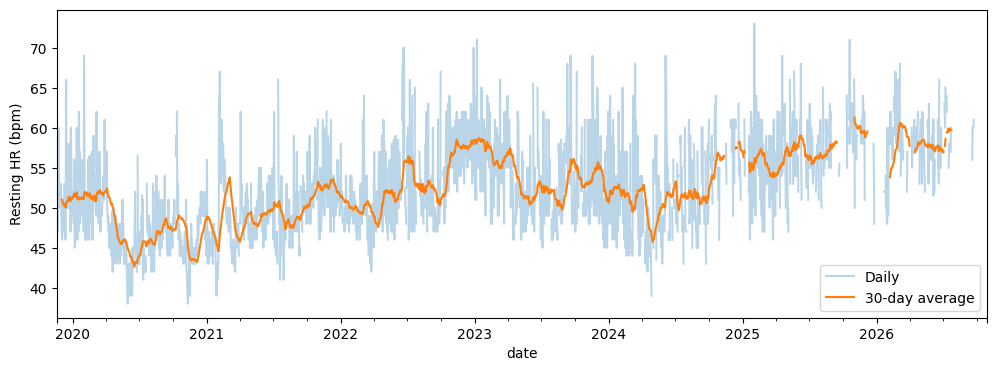

In [8]:

rhr_raw = pd.DataFrame(rhr_rows) # turns into a table with columns date and rhr
rhr_raw["date"] = pd.to_datetime(rhr_raw["date"]) # converts the date into real dates
rhr_raw = rhr_raw.groupby("date").mean() # if a day has more than one value, average them into one
rhr_daily = rhr_raw.asfreq("D") # empty rows for days with no value.
rhr_daily["rolling_30d"] = rhr_daily["rhr"].rolling('30D', min_periods=15).mean() # 30-day average
ax = rhr_daily["rhr"].plot(alpha=0.3, label="Daily", figsize=(12, 4)) 
rhr_daily["rolling_30d"].plot(ax=ax, label="30-day average")
ax.legend()
ax.set_ylabel("Resting HR (bpm)")

## HRV chart

Text(0, 0.5, 'HRV SDNN (ms)')

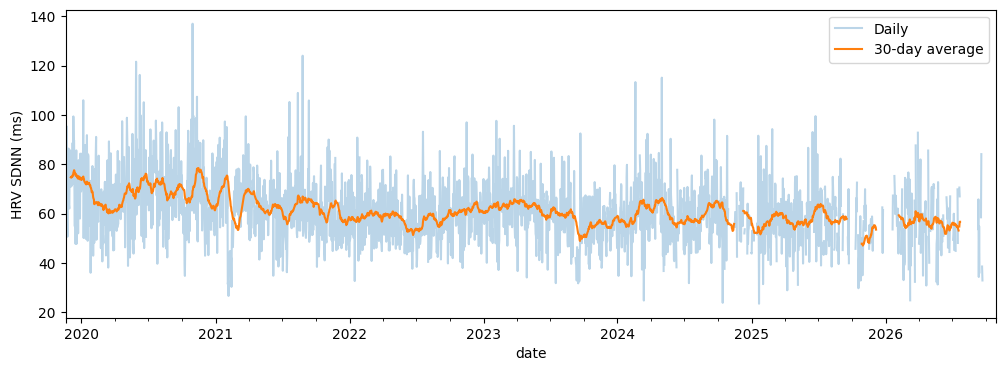

In [9]:
hrv_raw = pd.DataFrame(hrv_rows) # turns into a table with columns date and hrv
hrv_raw["date"] = pd.to_datetime(hrv_raw["date"]) # converts the date into real dates
hrv_raw = hrv_raw.groupby("date").mean() # if a day has more than one value, average them into one
hrv_daily = hrv_raw.asfreq("D") # empty rows for days with no value.
hrv_daily["rolling_30d"] = hrv_daily["hrv"].rolling('30D', min_periods=15).mean() # 30-day average
ax = hrv_daily["hrv"].plot(alpha=0.3, label="Daily", figsize=(12, 4)) 
hrv_daily["rolling_30d"].plot(ax=ax, label="30-day average")
ax.legend()
ax.set_ylabel("HRV SDNN (ms)")



## Training volume vs. resting heart rate

Text(0, 0.5, 'Resting HR, 30-day avg (bpm)')

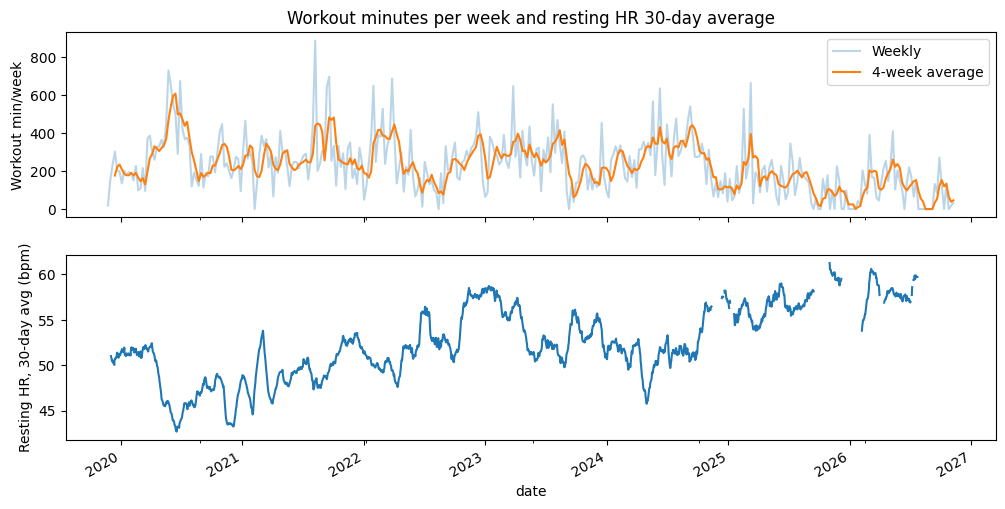

In [10]:
workouts = pd.DataFrame(workout_rows) # turns into a table
workouts["start"] = pd.to_datetime(workouts["start"]) # converts the date into real dates
workouts = workouts.set_index("start") # use "start" as index
weekly = workouts["duration_min"].resample("W").sum() # resample

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(12, 6)) # create layout
weekly.plot(ax=ax_top, alpha=0.3, label="Weekly", x_compat=True)
weekly.rolling(4).mean().plot(ax=ax_top, label="4-week average", x_compat=True)
ax_top.set_ylabel("Workout min/week")
ax_top.set_title("Workout minutes per week and resting HR 30-day average")
ax_top.legend()
rhr_daily["rolling_30d"].plot(ax=ax_bottom, x_compat=True)
ax_bottom.set_ylabel("Resting HR, 30-day avg (bpm)")
